## ДЗ№1

цель: Подобрать интересный набор данных и провести его EDA c использованием визуальных и статистических инструментов.

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('C:/Users/ogur4ik/Downloads/XAU_1d_data.csv', sep=';')

df['return'] = df['Close'].pct_change()
df['range'] = (df['High'] - df['Low']) / df['Close']
df = df.dropna()

df.head()

,Date,Open,High,Low,Close,Volume,return,range
1,2004.06.14 00:00,384.3,385.8,381.8,382.8,1902,-0.003385,0.010449
2,2004.06.15 00:00,382.8,388.8,381.1,388.6,1951,0.015152,0.019815
3,2004.06.16 00:00,387.1,389.8,382.6,383.8,2014,-0.012352,0.018760
4,2004.06.17 00:00,383.6,389.3,383.0,387.6,1568,0.009901,0.016254
5,2004.06.18 00:00,388.6,395.8,385.8,394.3,2257,0.017286,0.025361


## Корреляции

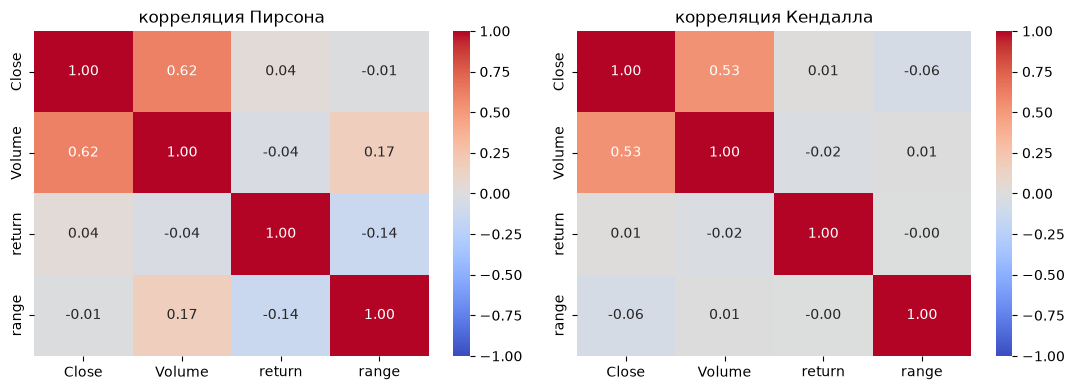

In [48]:
cols = ['Close', 'Volume', 'return', 'range']

corr_p = df[cols].corr()
corr_k = df[cols].corr(method='kendall')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(corr_p, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', ax=axes[0])
axes[0].set_title('корреляция Пирсона')

sns.heatmap(corr_k, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', ax=axes[1])
axes[1].set_title('корреляция Кендалла')

plt.tight_layout()
plt.show()

### значимость корреляции Пирсона

In [49]:
x = df['return']
y = df['range']
n = len(x)

r = np.corrcoef(x, y)[0, 1]
t_stat = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)
p_value = 2 * (1 - stats.t.cdf(np.abs(t_stat), df=n - 2))

print(f'r = {r:.4f}, t = {t_stat:.4f}, p-value = {p_value:.4e}')

r = -0.1384, t = -10.3895, p-value = 0.0000e+00


### проверка на нормальность

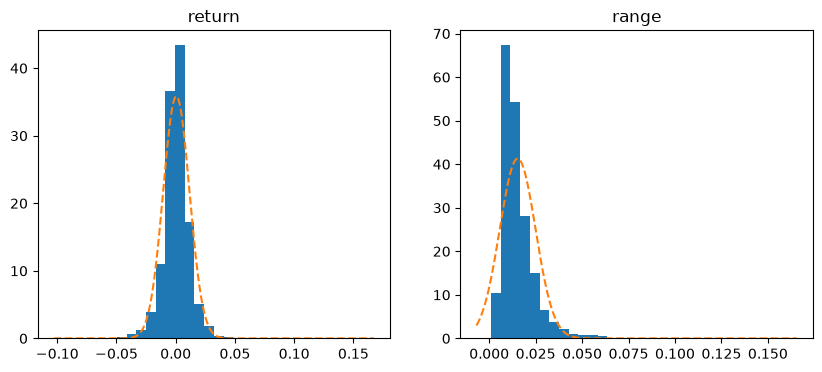

In [50]:
keys = ['return', 'range']
fig, axes = plt.subplots(ncols=len(keys), figsize=(10, 4))

for key, ax in zip(keys, axes):
    ax.hist(df[key], density=True, bins=30)
    loc = df[key].mean()
    scale = df[key].std()
    x_left, x_right = ax.get_xlim()
    x = np.linspace(x_left, x_right, 1000)
    y = stats.norm.pdf(x, loc=loc, scale=scale)
    ax.plot(x, y, linestyle='dashed')
    ax.set_title(key)

plt.show()

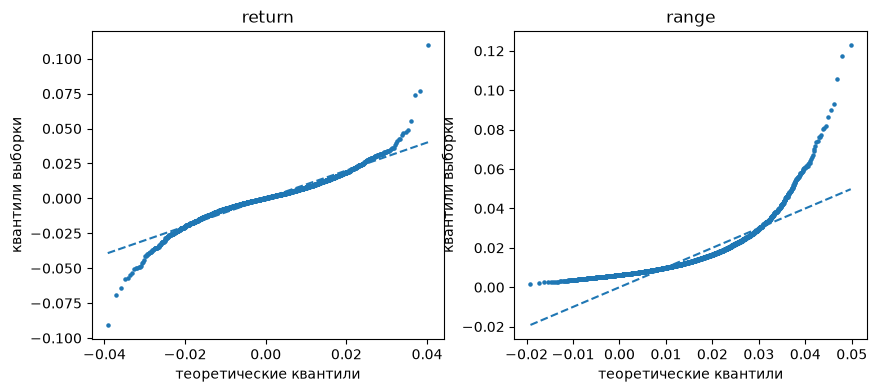

In [51]:
fig, axes = plt.subplots(ncols=len(keys), figsize=(10, 4))

for key, ax in zip(keys, axes):
    samples = df[key]
    loc = samples.mean()
    scale = samples.std()
    interval = np.linspace(0, 1, samples.shape[0])[1:-1]
    x = stats.norm.ppf(interval, loc=loc, scale=scale)
    y = np.quantile(samples, interval)
    ax.scatter(x, y, s=5)
    ax.plot(x, x, linestyle='dashed')
    ax.set_title(key)
    ax.set_xlabel('теоретические квантили')
    ax.set_ylabel('квантили выборки')

plt.show()

In [52]:
for key in keys:
    print(key)
    samples = df[key]
    loc = samples.mean()
    scale = samples.std()
    for i in range(1, 4):
        true_value = stats.norm.cdf(i) - stats.norm.cdf(-i)
        sample_value = ((samples >= loc - i * scale) & (samples <= loc + i * scale)).sum() / samples.shape[0]
        print(f'{i} sigma(s): theor={true_value:.4f}, sample={sample_value:.4f}')
    print()

return
1 sigma(s): theor=0.6827, sample=0.7709
2 sigma(s): theor=0.9545, sample=0.9508
3 sigma(s): theor=0.9973, sample=0.9875

range
1 sigma(s): theor=0.6827, sample=0.8532
2 sigma(s): theor=0.9545, sample=0.9618
3 sigma(s): theor=0.9973, sample=0.9823



### тесты Шапиро-Уилка и Колмогорова-Смирнова

In [53]:
for key in keys:
    samples = df[key]
    
    # Шапиро-Уилк (до 5000 значений из-за ограничения метода)
    w, p_shapiro = stats.shapiro(samples[:5000])
    
    # Колмогоров-Смирнов (без ошибки с ndtr)
    norm_dist = stats.norm(loc=samples.mean(), scale=samples.std())
    d, p_ks = stats.kstest(samples, norm_dist.cdf)
    
    print(f'{key}:')
    print(f'  Shapiro-Wilk:        p-value = {p_shapiro:.4e}')
    print(f'  Kolmogorov-Smirnov:  p-value = {p_ks:.4e}')

return:
  Shapiro-Wilk:        p-value = 3.5241e-39
  Kolmogorov-Smirnov:  p-value = 5.0622e-24
range:
  Shapiro-Wilk:        p-value = 1.7207e-63
  Kolmogorov-Smirnov:  p-value = 5.5867e-90


## Проверка гипотез
1. $H_1$: средняя доходность золота равна нулю
2. $H_2$: средняя внутридневная волатильность в дни роста равна средней волатильности в дни падения
3. $H_3$: реальный коэффициент корреляции между объемом торгов (Volume) и размахом цен (range) равен нулю ($r = 0$)

In [54]:
samples = df['return']
n = len(samples)
mu_0 = 0

t_stat = (samples.mean() - mu_0) / (samples.std(ddof=1) / np.sqrt(n))
p_left = stats.t.cdf(t_stat, df=n - 1)
p_right = 1 - stats.t.cdf(t_stat, df=n - 1)
pvalue = 2 * min(p_left, p_right)

print(f'mean = {samples.mean():.6f}, t = {t_stat:.4f}, p-value = {pvalue:.4f}')

mean = 0.000522, t = 3.4867, p-value = 0.0005


In [55]:
up_days = df[df['return'] > 0]['range']
down_days = df[df['return'] < 0]['range']

t_stat, p_val = stats.ttest_ind(up_days, down_days, equal_var=False)
print(f't-статистика: {t_stat:.4f}, p-value: {p_val:.4f}')

t-статистика: -5.1119, p-value: 0.0000


In [63]:
down_range = df[df['return'] < 0]['range']
up_range = df[df['return'] > 0]['range']

p = 0.95
alpha = 1 - p
mean = samples.mean()
std = samples.std(ddof=1)

t = stats.t.ppf(1 - alpha / 2, df=n - 1)

diff_mean = down_range.mean() - up_range.mean()
se_diff = np.sqrt(down_range.var(ddof=1)/len(down_range) + up_range.var(ddof=1)/len(up_range))

ci_diff = (diff_mean - t * se_diff, diff_mean + t * se_diff)
print(f'95% доверительный интервал для превышения волатильности в дни падения: ({ci_diff[0]*100:.3f}%, {ci_diff[1]*100:.3f}%)')

95% доверительный интервал для превышения волатильности в дни падения: (0.083%, 0.187%)


In [57]:
vol = df['Volume']
rng = df['range']
n_obs = len(vol)

r_val = np.corrcoef(vol, rng)[0, 1]
t_stat = r_val * np.sqrt(n_obs - 2) / np.sqrt(1 - r_val**2)
p_val = 2 * (1 - stats.t.cdf(np.abs(t_stat), df=n_obs - 2))

print(f'r: {r_val:.4f}, t-статистика: {t_stat:.4f}, p-value: {p_val:.4e}')

r: 0.1659, t-статистика: 12.5113, p-value: 0.0000e+00


In [65]:
p = 0.95
alpha = 1 - p
mean = samples.mean()
std = samples.std(ddof=1)

t = stats.t.ppf(1 - alpha / 2, df=n - 1)

ci = (mean - t * std / np.sqrt(n), mean + t * std / np.sqrt(n))
print(f'95% доверительный интервал для средней доходности: ({ci_diff[0]:.5f}%, {ci_diff[1]:.5f}%)')

95% доверительный интервал для средней доходности: (0.00083%, 0.00187%)
